# Toy example: fatigue crack growth (Paris-Erdogan law)

A self-contained illustration of the data-fusion methodology of the package `bayes_fusion`, on a
fictitious material whose crack grows according to Paris' law, integrated with an explicit Euler
scheme. It runs in well under a minute and needs no external data.

$$\frac{da}{dN} = C\,(\Delta K)^m, \qquad \Delta K = Y\,(\sigma_{\max}-\sigma_{\min})\sqrt{\pi a},$$

with six uncertain parameters $\theta=(C, m, \sigma_{\max}, \sigma_{\min}, Y, a_0)$ and failure when the crack
reaches $a_{\max}=50$ mm. Four heterogeneous sources of crack-length measurements (different sizes
and noise levels) are available over the first part of the life; the goal is the remaining useful
life (RUL) after the last measurement.

The steps are the ones of the article:

1. **Prior** uncertainty propagation through the simulator;
2. **HSIC** screening selects the parameter the data are most informative about;
3. **Calibration** of that parameter by RWMH-MCMC, where an ensemble of equally valid surrogates
   (polynomial chaos expansions of different degree) is aggregated in the likelihood with a fixed
   scrambled-Sobol design of weights;
4. the posterior replaces the prior of that parameter, the design of experiments is regenerated, and
   steps 2-3 repeat until the calibration no longer moves the prior (Kullback-Leibler criterion);
5. **Ensemble Kalman smoothing** of the posterior trajectories against the data, and the RUL
   distribution at each stage (prior, posterior, posterior + smoothing).

In [1]:
import numpy as np
import openturns as ot
import matplotlib.pyplot as plt

from bayes_fusion import (BayesCalibrationMCMC, RestrictedModel, ensemble_kalman_smoother,
                          estimate_kl, first_crossing_rul, select_active_index)
from bayes_fusion.metamodels import VPCEMetamodel

plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})
ot.RandomGenerator.SetSeed(42)
rng = np.random.default_rng(42)

## 1. The simulator and the prior

`paris_growth` integrates the law for a whole sample of parameters at once on a fixed grid of
cycles (beyond $a_{\max}$ the crack length is only capped, for numerical safety).

In [2]:
PARAM_NAMES = ['C', 'm', 'sigma_max', 'sigma_min', 'Y', 'a0']
PARAM_LABELS = [r'$C$', r'$m$', r'$\sigma_{\max}$', r'$\sigma_{\min}$', r'$Y$', r'$a_0$']

DELTA_N = 1000            # cycles per Euler step
N_STEPS = 200             # -> 200 000 cycles
A_MAX = 0.05              # critical crack length (m)
A_CAP = 10 * A_MAX        # numerical cap once the component has failed (keeps Euler finite)
N_GRID = DELTA_N * np.arange(N_STEPS + 1)


def paris_growth(theta):
    # theta: (n, 6) -> crack length (n, N_STEPS + 1), explicit Euler, capped at A_MAX
    C, m, s_max, s_min, Y, a0 = np.atleast_2d(theta).T
    a = np.empty((C.size, N_STEPS + 1))
    a[:, 0] = a0
    for t in range(N_STEPS):
        dK = Y * (s_max - s_min) * np.sqrt(np.pi * a[:, t])
        a[:, t + 1] = np.minimum(a[:, t] + C * dK ** m * DELTA_N, A_CAP)
    return a


# fictitious material: nominal values, +-10 % (or small absolute) uniform uncertainty
nominal = np.array([1e-10, 3.0, 100.0, 10.0, 1.1, 1e-3])
half_width = np.array([1e-11, 0.1, 5.0, 1.0, 0.01, 1e-4])
BOUNDS = [(c - h, c + h) for c, h in zip(nominal, half_width)]


def prior_marginals():
    return [ot.Uniform(lo, hi) for lo, hi in BOUNDS]


theta_true = np.array([1.07e-10, 3.04, 102.5, 9.6, 1.104, 1.08e-3])   # the 'real' component
a_true = paris_growth(theta_true)[0]
N_fail_true = first_crossing_rul(a_true[None, :], N_GRID, A_MAX)[0]
print(f'true failure after {N_fail_true:,.0f} cycles')

true failure after 77,000 cycles


## 2. Heterogeneous data

Four sources measure the crack length with different noise levels and different numbers of points,
all before 80 % of the true life. The model output is always read on the same sorted timeline, and
`time_indices` records which positions of that timeline belong to each source -- the structure
expected by `BayesCalibrationMCMC`.

In [3]:
n_per_source = [3, 4, 2, 13]
noise_std = np.array([0.0005, 0.001, 0.002, 0.001])        # measurement noise of each source (m)

i_fail = int(N_fail_true // DELTA_N)
pool = np.arange(int(0.25 * i_fail), int(0.8 * i_fail))
obs_idx = np.sort(rng.choice(pool, size=sum(n_per_source), replace=False))   # grid indices, all distinct
source_of = rng.permutation(np.repeat(np.arange(len(n_per_source)), n_per_source))

data_with_time_division, time_indices, obs_columns = [], [], []
for j, s in enumerate(noise_std):
    cols = obs_idx[source_of == j]                                 # grid columns of source j (sorted)
    vals = a_true[cols] + rng.normal(0.0, s, size=cols.size)
    data_with_time_division.append(np.column_stack([N_GRID[cols], vals]))
    time_indices.append(np.searchsorted(obs_idx, cols))            # positions in the sorted timeline
    obs_columns.append(cols)

N_last_obs = N_GRID[obs_idx[-1]]
true_rul = N_fail_true - N_last_obs
print('points per source:', [len(d) for d in data_with_time_division],
      f'| last measurement at {N_last_obs:,.0f} cycles | true RUL = {true_rul:,.0f} cycles')

points per source: [3, 4, 2, 13] | last measurement at 60,000 cycles | true RUL = 17,000 cycles


## 3. Prior uncertainty propagation

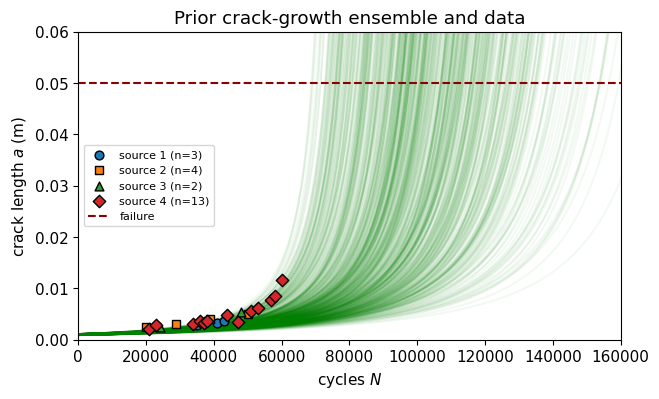

In [4]:
N_DOE = 600
prior_sample = np.asarray(ot.JointDistribution(prior_marginals()).getSample(N_DOE))
prior_traj = paris_growth(prior_sample)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(N_GRID, prior_traj.T, color='green', alpha=0.05)
markers = ['o', 's', '^', 'D']
for j, d in enumerate(data_with_time_division):
    ax.scatter(d[:, 0], d[:, 1], marker=markers[j], s=40, edgecolors='k', zorder=5,
               label=f'source {j + 1} (n={len(d)})')
ax.axhline(A_MAX, color='darkred', ls='--', label='failure')
ax.set_xlim(0, 160000); ax.set_ylim(0, 0.06)
ax.set_xlabel('cycles $N$'); ax.set_ylabel('crack length $a$ (m)')
ax.set_title('Prior crack-growth ensemble and data'); ax.legend(fontsize=8)
plt.show()

## 4. Sequential calibration

At each iteration: HSIC picks the active parameter, three polynomial-chaos surrogates (total degree
2, 3 and 4, fitted by least squares with LARS selection) emulate the simulator at the measurement
times, and the MCMC samples the aggregated posterior of the active parameter. `RestrictedModel`
freezes the other inputs at their sample mean.

In [5]:
DEGREES = [2, 3, 4]
MAX_ITER, KL_TOL = 5, 5e-3

marginals = prior_marginals()
history = []

for it in range(MAX_ITER):
    # design of experiments from the current prior, observed at the measurement times
    X = np.asarray(ot.JointDistribution(marginals).getSample(N_DOE))
    y = paris_growth(X)[:, obs_idx]

    active = select_active_index(X, y)
    lo = marginals[active].getRange().getLowerBound()[0]
    hi = marginals[active].getRange().getUpperBound()[0]

    # ensemble of equally valid surrogates (basis orthogonal w.r.t. the original prior)
    surrogates = []
    for deg in DEGREES:
        s = VPCEMetamodel(degree=deg, q_norm=1.0, input_dimension=len(BOUNDS),
                          prior_distribution_list=prior_marginals(), verbose=False)
        s.fit(X, y)
        surrogates.append(s)
    models = [RestrictedModel(s, active, X.mean(axis=0)) for s in surrogates]

    bayes = BayesCalibrationMCMC(data=data_with_time_division, data_time_indices=time_indices,
                                 metamodels=models, scalers=[None] * len(models))
    posterior = bayes.mcmc_run(support_min=[lo], support_max=[hi],
                               proposal=ot.Uniform(-0.1 * (hi - lo), 0.1 * (hi - lo)),
                               burning=100, n_chains=3, sample_size=1000, nb_weights=1024)

    kl = estimate_kl(posterior, marginals[active], n_samples=10000, bins=50)
    history.append(dict(iteration=it + 1, active=PARAM_NAMES[active], kl=kl,
                        post_mean=float(np.mean(posterior.getSample(2000))), true=theta_true[active]))
    print(f"iteration {it + 1}: active parameter = {PARAM_NAMES[active]:<9s} KL(posterior||prior) = {kl:.3f}")
    if kl < KL_TOL or np.isinf(kl):      # calibration no longer moves the prior
        break
    marginals[active] = posterior

Running Markov chain 0
Running Markov chain 1
Running Markov chain 2
Gelman-Rubin convergence diagnostic: 1.0158501450195947
iteration 1: active parameter = m         KL(posterior||prior) = 2.420
Running Markov chain 0
Running Markov chain 1
Running Markov chain 2
Gelman-Rubin convergence diagnostic: 1.008847108959373
iteration 2: active parameter = sigma_max KL(posterior||prior) = 1.207
Running Markov chain 0
Running Markov chain 1
Running Markov chain 2
Gelman-Rubin convergence diagnostic: 1.0015767661489094
iteration 3: active parameter = a0        KL(posterior||prior) = 1.069
Running Markov chain 0
Running Markov chain 1
Running Markov chain 2
Gelman-Rubin convergence diagnostic: 1.0026039933291584
iteration 4: active parameter = C         KL(posterior||prior) = 1.077
Running Markov chain 0
Running Markov chain 1
Running Markov chain 2
Gelman-Rubin convergence diagnostic: 0.9998280353732707
iteration 5: active parameter = sigma_max KL(posterior||prior) = inf


In [6]:
import pandas as pd
pd.DataFrame(history).style.format({'kl': '{:.3f}', 'post_mean': '{:.4g}', 'true': '{:.4g}'})

,iteration,active,kl,post_mean,true
0,1,m,2.420,3.091,3.04
1,2,sigma_max,1.207,103.6,102.5
2,3,a0,1.069,0.001012,0.00108
3,4,C,1.077,9.936e-11,1.07e-10
4,5,sigma_max,inf,103.4,102.5


## 5. Posterior parameters and trajectories

The posterior ensemble `post_traj` is obtained by running the simulator on samples of the refined
joint distribution; the ensemble Kalman smoother then conditions it on each source in turn (the
observations of source $j$ sit at columns `obs_columns[j]` of the trajectory ensemble).

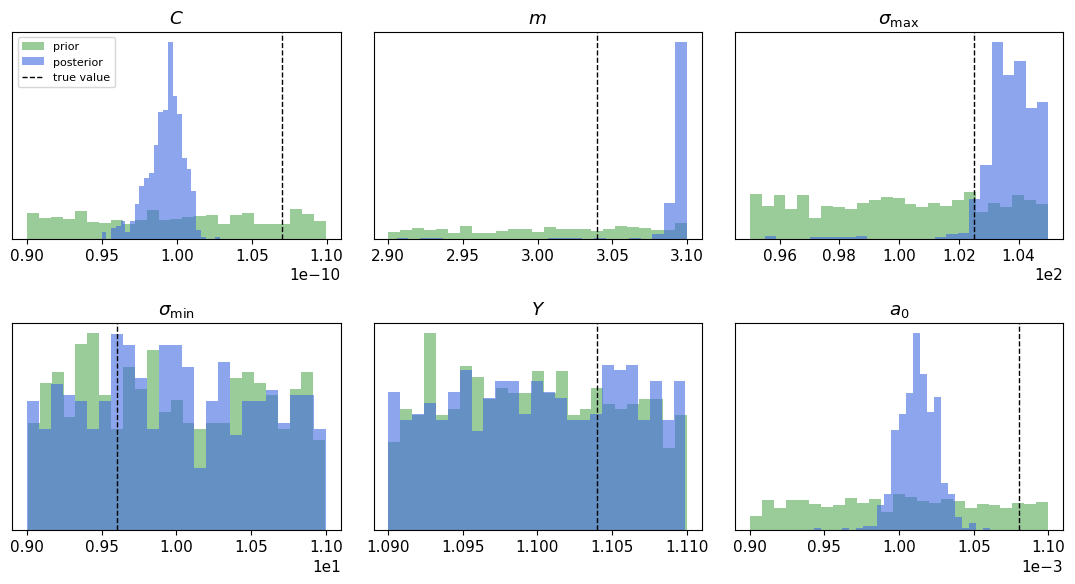

In [7]:
posterior_sample = np.asarray(ot.JointDistribution(marginals).getSample(N_DOE))
post_traj = paris_growth(posterior_sample)

smoothed = post_traj
for j, s in enumerate(noise_std):
    obs_values = np.zeros(N_STEPS + 1)
    obs_values[obs_columns[j]] = data_with_time_division[j][:, 1]
    smoothed = ensemble_kalman_smoother(smoothed, obs_columns[j], obs_values, obs_std=s)

fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for k, ax in enumerate(axes.ravel()):
    ax.hist(prior_sample[:, k], bins=25, density=True, color='green', alpha=0.4, label='prior')
    ax.hist(posterior_sample[:, k], bins=25, density=True, color='royalblue', alpha=0.6, label='posterior')
    ax.axvline(theta_true[k], color='k', ls='--', lw=1, label='true value')
    ax.set_title(PARAM_LABELS[k]); ax.set_yticks([])
    ax.ticklabel_format(style='sci', axis='x', scilimits=(0, 0))
axes[0, 0].legend(fontsize=8)
fig.tight_layout(); plt.show()

**Note.** The marginal posteriors need not cover the true values: $C$, $m$, $\sigma_{\max}$ and $a_0$
all act on the same growth rate, so the data constrain a *combination* of them, and the sequential
single-parameter calibration compensates by moving the parameters it is allowed to move (some
end up against a bound of their prior). The quantity of interest for prognostics is the calibrated
trajectory, hence the RUL, shown next.

## 6. Remaining useful life

The RUL is the number of cycles between the last measurement and the first crossing of $a_{\max}$,
for the prior ensemble, the calibrated (posterior) ensemble and the smoothed ensemble.

true RUL: 17,000 cycles
Prior              mean    44,683 | std   18,778 | 5-95 %:    16,000 -    76,100
Posterior          mean    14,845 | std    5,754 | 5-95 %:    10,000 -    20,000
Posterior + EnKS   mean    14,063 | std    1,034 | 5-95 %:    12,000 -    15,000


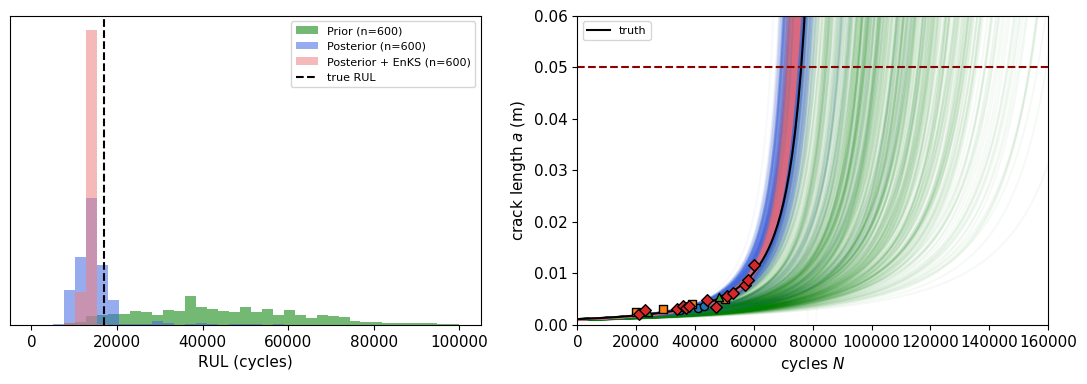

In [8]:
i0 = int(obs_idx[-1])                      # start of the prognostics window = last measurement
stages = {'Prior': prior_traj, 'Posterior': post_traj, 'Posterior + EnKS': smoothed}
colors = {'Prior': 'green', 'Posterior': 'royalblue', 'Posterior + EnKS': 'lightcoral'}
rul = {k: first_crossing_rul(v[:, i0:], N_GRID[i0:], A_MAX) for k, v in stages.items()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(0, 1.0e5, 40)
for k, r in rul.items():
    axes[0].hist(r, bins=bins, density=True, alpha=0.55, color=colors[k], label=f'{k} (n={len(r)})')
axes[0].axvline(true_rul, color='k', ls='--', label='true RUL')
axes[0].set_xlabel('RUL (cycles)'); axes[0].set_yticks([]); axes[0].legend(fontsize=8)

for k, v in stages.items():
    axes[1].plot(N_GRID, v.T, color=colors[k], alpha=0.04)
for j, d in enumerate(data_with_time_division):
    axes[1].scatter(d[:, 0], d[:, 1], marker=markers[j], s=35, edgecolors='k', zorder=5)
axes[1].plot(N_GRID, a_true, color='k', lw=1.5, label='truth')
axes[1].axhline(A_MAX, color='darkred', ls='--')
axes[1].set_xlim(0, 160000); axes[1].set_ylim(0, 0.06)
axes[1].set_xlabel('cycles $N$'); axes[1].set_ylabel('crack length $a$ (m)'); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

print(f"true RUL: {true_rul:,.0f} cycles")
for k, r in rul.items():
    print(f"{k:<18s} mean {r.mean():9,.0f} | std {r.std():8,.0f} | 5-95 %: {np.quantile(r, .05):9,.0f} - {np.quantile(r, .95):9,.0f}")

**Reading the figure.** The prior RUL is wide. Calibrating the parameters the data are informative
about brings the distribution much closer to the true RUL, and the smoothing step further reduces its
dispersion by conditioning the trajectories on the measurements themselves. The smoothed ensemble is
the narrowest and can be over-confident (it ignores the remaining model and surrogate error), which
is why the methodology reports the three stages side by side.